In [ ]:
# https://www.kaggle.com/crowdflower/twitter-airline-sentiment
#!wget -nc https://lazyprogrammer.me/course_files/AirlineTweets.csv

--2024-03-12 21:21:20--  https://lazyprogrammer.me/course_files/AirlineTweets.csv
Resolving lazyprogrammer.me (lazyprogrammer.me)... 104.21.23.210, 172.67.213.166, 2606:4700:3031::6815:17d2, ...
Connecting to lazyprogrammer.me (lazyprogrammer.me)|104.21.23.210|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3421431 (3.3M) [text/csv]
Saving to: ‘AirlineTweets.csv’

AirlineTweets.csv   100%[===================>]   3.26M  --.-KB/s    in 0.06s   

2024-03-12 21:21:21 (55.6 MB/s) - ‘AirlineTweets.csv’ saved [3421431/3421431]



In [4]:
import numpy as np
import pandas as pd
import seaborn as sn
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix

from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Model
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.optimizers import Adam

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)           │ (None, 2000)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │           2,001 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,001 (7.82 KB)

 Trainable params: 2,001 (7.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7920 - loss: 0.5050 - val_accuracy: 0.8049 - val_loss: 0.3973
Epoch 2/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7970 - loss: 0.3754 - val_accuracy: 0.8219 - val_loss: 0.3394
Epoch 3/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8213 - loss: 0.3218 - val_accuracy: 0.8416 - val_loss: 0.3023
Epoch 4/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8460 - loss: 0.2845 - val_accuracy: 0.8614 - val_loss: 0.2766
Epoch 5/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8644 - loss: 0.2572 - val_accuracy: 0.8773 - val_loss: 0.2580
Epoch 6/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8812 - loss: 0.2364 - val_accuracy: 0.8881 - val_loss: 0.2441
Epoch 7/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8931 - loss: 0.2199 - val_accuracy: 0.8999 - val_loss: 0.2334
Epoch 8/40
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9019 - loss: 0.2065 - val_accuracy: 0.9040 - val_loss:

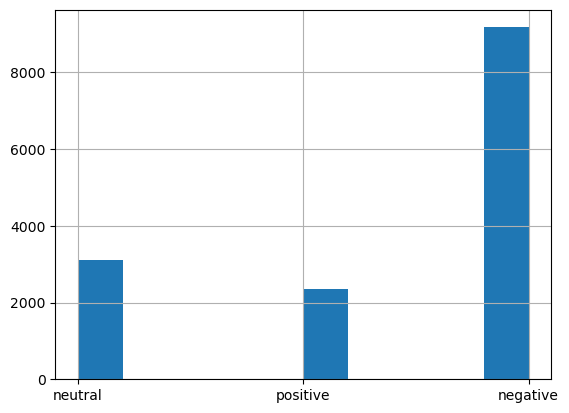

In [9]:
np.random.seed(0)
tf.random.set_seed(0)

df = pd.read_csv('AirlineTweets.csv')

df.head()

df = df[['airline_sentiment', 'text']]

df['airline_sentiment'].hist()

df = df[df['airline_sentiment'] != 'neutral'].copy()

target_map = {'positive': 1, 'negative': 0}
df['target'] = df['airline_sentiment'].map(target_map)

df.head()

df_train, df_test = train_test_split(df, random_state=42)

vectorizer = TfidfVectorizer(max_features=2000)
X_train = vectorizer.fit_transform(df_train['text'])
X_test = vectorizer.transform(df_test['text'])

# data must not be sparse matrix before passing into tensorflow
X_train = X_train.toarray()
X_test = X_test.toarray()

Y_train = df_train['target']
Y_test = df_test['target']

# input dimensions
D = X_train.shape[1]

# build model
i = Input(shape=(D,))
x = Dense(1)(i) # sigmoid included in loss

model = Model(i, x)

model.summary()

model.compile(
  loss=BinaryCrossentropy(from_logits=True),
  optimizer=Adam(learning_rate=0.01),
  metrics=['accuracy']
)

r = model.fit(
  X_train, Y_train,
  validation_data=(X_test, Y_test),
  epochs=40,
  batch_size=128,
)

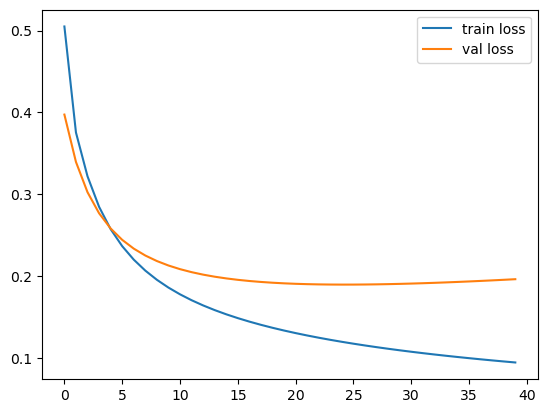

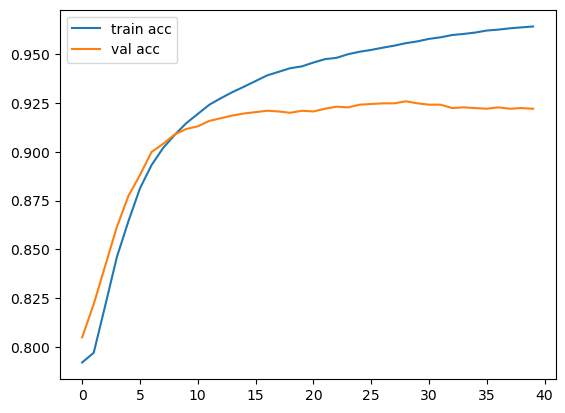

271/271 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


array([[0.99037199, 0.00962801],
       [0.09777778, 0.90222222]])

In [10]:
# Plot loss per iteration
plt.plot(r.history['loss'], label='train loss')
plt.plot(r.history['val_loss'], label='val loss')
plt.legend();
plt.show()

# Plot accuracy per iteration
plt.plot(r.history['accuracy'], label='train acc')
plt.plot(r.history['val_accuracy'], label='val acc')
plt.legend();
plt.show()

P_train = ((model.predict(X_train) > 0) * 1.0).flatten()
P_test = ((model.predict(X_test) > 0) * 1.0).flatten()

cm = confusion_matrix(Y_train, P_train, normalize='true')
cm

271/271 ━━━━━━━━━━━━━━━━━━━━ 0s 938us/step
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Train AUC: 0.9948807034605721
Test AUC: 0.9534793389756769
Train F1: 0.9306590257879657
Test F1: 0.7906103286384977
Most positive words:
thank 9.828968
thanks 9.432877
worries 8.642617
great 8.106754
love 7.455918
awesome 7.385801
excellent 7.158479
kudos 6.743794
amazing 6.4513326
best 6.182436
Most negative words:
worst -9.271048
paid -7.906892
not -7.7974277
rude -7.5941544
nothing -6.949345
disappointed -6.9298954
website -6.775517
hung -6.761382
instead -6.5330625
weren -6.186504


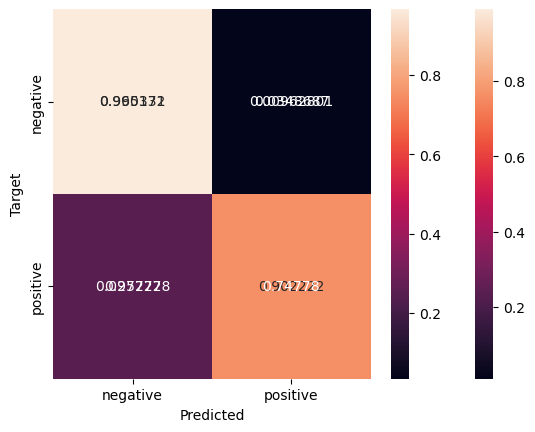

In [11]:
# Scikit-Learn is transitioning to V1 but it's not available on Col...
# The changes modify how confusion matrices are plotted
def plot_cm(cm):
  classes = ['negative', 'positive']
  df_cm = pd.DataFrame(cm, index=classes, columns=classes)
  ax = sn.heatmap(df_cm, annot=True, fmt='g')
  ax.set_xlabel("Predicted")
  ax.set_ylabel("Target")

plot_cm(cm)

cm_test = confusion_matrix(Y_test, P_test, normalize='true')
plot_cm(cm_test)

Pr_train = model.predict(X_train)
Pr_test = model.predict(X_test)
print("Train AUC:", roc_auc_score(Y_train, Pr_train))
print("Test AUC:", roc_auc_score(Y_test, Pr_test))

print("Train F1:", f1_score(Y_train, P_train))
print("Test F1:", f1_score(Y_test, P_test))

model.layers

model.layers[1].get_weights()

w = model.layers[1].get_weights()[0]

word_index_map = vectorizer.vocabulary_
word_index_map

# let's look at the weights for each word
# try it with different threshold values!
threshold = 2

print("Most positive words:")
word_weight_tuples = []
for word, index in word_index_map.items():
    weight = w[index, 0]
    if weight > threshold:
        word_weight_tuples.append((word, weight))

word_weight_tuples = sorted(word_weight_tuples, key=lambda x: -x[1])
for i in range(10):
  word, weight = word_weight_tuples[i]
  print(word, weight)

print("Most negative words:")
word_weight_tuples = []
for word, index in word_index_map.items():
    weight = w[index, 0]
    if weight < -threshold:
        word_weight_tuples.append((word, weight))

word_weight_tuples = sorted(word_weight_tuples, key=lambda x: x[1])
for i in range(10):
  word, weight = word_weight_tuples[i]
  print(word, weight)

# Exercise: apply to spam detection

In [ ]:
# Exercise: apply to spam detection

![](https://deeplearningcourses.com/notebooks_v3_pxl?sc=MJHxClvYWOEUA8PFd__U7w&n=TF2+Classification)